## **ML Mini Project Phase 1**
### **Team Members**:- Vishal Shinde(251090700194) And Sumit Patil(251090700100) 
### MCA - A 
### Batch - A2

## **Dataset And Overview:-**
#### **Dataset**:- Chronic Kidney Disease Dataset 
#### **Link Of Dataset** :- https://www.kaggle.com/datasets/rabieelkharoua/chronic-kidney-disease-dataset-analysis

### **Problem Statement**
#### Develop and evaluate machine learning approaches that classify the dataset's 'Diagnosis' label from selected patient and laboratory features. The label's clinical meaning must be confirmed from the dataset documentation before interpreting it as Chronic Kidney Disease.

### **Objectives**
#### 1.) Inspect the dataset metadata and data quality.
#### 2.)  Explore target distribution, feature statistics, missingness, correlations and possible outliers.
#### 3.)  Select a practical initial set of 21 input features for a report upload plus questionnaire workflow.
#### 4.)  Shortlist six models for Phase 2 including at least two ensemble models.
####  Why 21 features instead of 51?
#### The full dataset contains 51 candidate predictors after excluding PatientID, DoctorInCharge and Diagnosis. The 21 feature subset is a practical starting point for deployment. It emphasizes kidney related lab results, demographics, blood pressure and a small set of medical history features that can potentially be obtained from reports or a short questionnaire. It reduces input burden and simplifies report extraction.

In [ ]:
# Essential Imports:- 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib     
# Saves and loads trained ML models so they can be reused without retraining.
import warnings
warnings.filterwarnings('ignore')    
# Controls warning messages displayed during execution, allowing you to ignore unnecessary warnings.


# Scikit-Learn Preprocessing & Model Selection:- 

from sklearn.model_selection import(
train_test_split, 
StratifiedKFold, 
# Splits data into folds while maintaining class proportions for reliable model evaluation.
cross_val_score)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer    
# Fills missing values using values from the nearest, most similar data points.
from sklearn.pipeline import Pipeline

# 4 Normal Models:- 

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# 2 Ensemble Models:- 

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation Metrics:- 

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)



In [5]:
# Dataset And Metadata

df = pd.read_csv('Chronic_Kidney_Dsease_data.csv')
df.head()

df.info()
display(df.describe())
display(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 1659 entries, 0 to 1658
Data columns (total 54 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PatientID                      1659 non-null   int64  
 1   Age                            1659 non-null   int64  
 2   Gender                         1659 non-null   int64  
 3   Ethnicity                      1659 non-null   int64  
 4   SocioeconomicStatus            1659 non-null   int64  
 5   EducationLevel                 1659 non-null   int64  
 6   BMI                            1659 non-null   float64
 7   Smoking                        1659 non-null   int64  
 8   AlcoholConsumption             1659 non-null   float64
 9   PhysicalActivity               1659 non-null   float64
 10  DietQuality                    1659 non-null   float64
 11  SleepQuality                   1659 non-null   float64
 12  FamilyHistoryKidneyDisease     1659 non-null   int64  
 13 

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,MuscleCramps,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis
count,1659.000000,1659.000000,1659.000000,1659.00000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,...,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000
mean,830.000000,54.441230,0.515371,0.71308,0.977697,1.693189,27.620049,0.292948,9.969831,5.024247,...,3.525510,5.054869,49.730659,0.044002,0.103074,0.197107,2.000336,4.947788,5.144973,0.918626
std,479.056364,20.549757,0.499914,1.00043,0.776686,0.910611,7.288670,0.455252,5.798787,2.866274,...,2.026131,2.880460,27.827593,0.205162,0.304147,0.397934,1.141635,2.869959,2.901138,0.273492
min,1.000000,20.000000,0.000000,0.00000,0.000000,0.000000,15.033888,0.000000,0.021740,0.001186,...,0.006327,0.013697,0.087256,0.000000,0.000000,0.000000,0.001082,0.005392,0.004436,0.000000
25%,415.500000,36.000000,0.000000,0.00000,0.000000,1.000000,21.471449,0.000000,5.051156,2.555038,...,1.820793,2.532867,26.991708,0.000000,0.000000,0.000000,1.005802,2.498119,2.569561,1.000000
50%,830.000000,54.000000,1.000000,0.00000,1.000000,2.000000,27.652077,0.000000,9.951503,5.072395,...,3.572522,5.087086,48.970075,0.000000,0.000000,0.000000,2.040635,4.974069,5.182949,1.000000
75%,1244.500000,72.000000,1.000000,1.00000,2.000000,2.000000,34.015849,1.000000,14.967100,7.460563,...,5.254956,7.552093,73.913997,0.000000,0.000000,0.000000,2.947213,7.499783,7.733253,1.000000
max,1659.000000,90.000000,1.000000,3.00000,2.000000,3.000000,39.993532,1.000000,19.992713,9.998167,...,6.984636,9.998313,99.987510,1.000000,1.000000,1.000000,3.999469,9.992345,9.993754,1.000000


(1659, 54)

In [9]:
print('DATASET METADATA SUMMARY')
print('-'*65)
print("Total Rows (Patients) = ",df.shape[0])
print("Total Columns = ", df.shape[1]," (51 X Features + 2 IDs + 1 Target Y)")
print("Total Missing Values = ", df.isnull().sum().sum())
print("Duplicate Rows = ", df.duplicated().sum())
print('\nData Types Breakdown:')
print(df.dtypes.value_counts())

print('\nTarget Variable (Diagnosis) Distribution:')
target_counts = df['Diagnosis'].value_counts()
target_pct = (df['Diagnosis'].value_counts(normalize=True) * 100).round(2)
metadata_target = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
metadata_target.index = ['1 (CKD Positive)', '0 (No CKD)']
display(metadata_target)

DATASET METADATA SUMMARY
-----------------------------------------------------------------
Total Rows (Patients) =  1659
Total Columns =  54  (51 X Features + 2 IDs + 1 Target Y)
Total Missing Values =  0
Duplicate Rows =  0

Data Types Breakdown:
float64    30
int64      23
str         1
Name: count, dtype: int64

Target Variable (Diagnosis) Distribution:


,Count,Percentage (%)
1 (CKD Positive),1524,91.86
0 (No CKD),135,8.14


## Exploratory Data Analysis (EDA)
1. **Extraction Of 21 Features**
1. **Target Class Distribution** (`Diagnosis`)
2. **Outlier & Scale Inspection** via Boxplots

Original X Features      : 51
Noisy Features Removed   : 30
Final Selected X Features: 21
Number of X features: 21
X shape: (1659, 21) | y shape: (1659,)

Summary Statistics:


,count,mean,50%,std,min,max
SerumCreatinine,1659.0,2.75,2.73,1.32,0.50,5.00
GFR,1659.0,66.83,66.56,30.05,15.11,119.92
BUNLevels,1659.0,27.58,28.08,12.81,5.00,49.99
ProteinInUrine,1659.0,2.49,2.51,1.45,0.00,5.00
ACR,1659.0,149.88,150.20,86.85,0.18,299.58
HemoglobinLevels,1659.0,13.93,13.91,2.34,10.00,18.00
SerumElectrolytesPotassium,1659.0,4.51,4.51,0.58,3.50,5.50
SerumElectrolytesPhosphorus,1659.0,3.51,3.51,0.58,2.50,4.50
HbA1c,1659.0,6.98,6.99,1.73,4.00,10.00
FastingBloodSugar,1659.0,132.53,131.48,36.56,70.04,199.96



Missing values in selected features: 0


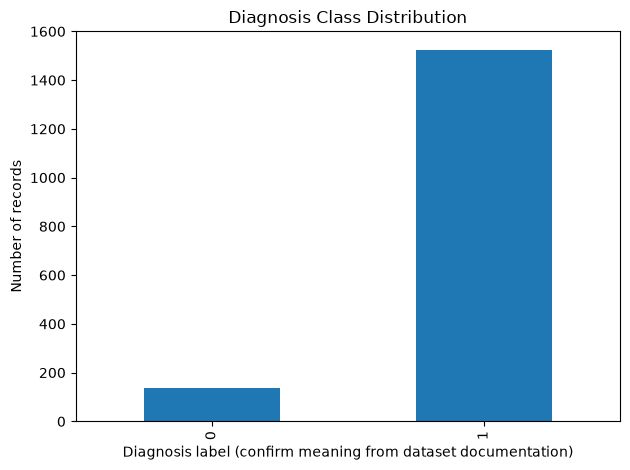

In [16]:
# The dataset contains a moderate imbalance ratio of roughly 91:9. We prioritized feature reduction and robust cross-validation 
# and models like Random Forest and Logistic Regression naturally achieved high F1-scores 
# and ROC-AUC metrics without requiring artificial synthetic data generation."

# Drop Identifier Columns
df_clean = df.drop(columns=['PatientID', 'DoctorInCharge'])

# Select the 21 High-Priority Clinical X Features (Data Reduction)
selected_21_features = [
    # Group 1: Kidney & Laboratory Results (10)
    'SerumCreatinine', 'GFR', 'BUNLevels', 'ProteinInUrine', 'ACR',
    'HemoglobinLevels', 'SerumElectrolytesPotassium', 'SerumElectrolytesPhosphorus',
    'HbA1c', 'FastingBloodSugar',
    # Group 2: Demographics & Measurements (5)
    'Age', 'Gender', 'BMI', 'SystolicBP', 'DiastolicBP',
    # Group 3: Medical History & Symptoms (6)
    'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension',
    'FamilyHistoryDiabetes','PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'Edema'
]

# Select X features and y target
X = df_clean[selected_21_features].copy()
y = df_clean['Diagnosis'].copy()

# Convert X features to numeric; invalid values become NaN
X = X.apply(pd.to_numeric, errors='coerce')

# Convert target to integer
y = pd.to_numeric(y, errors='raise').astype(int)

# Display feature selection summary
print(f'Original X Features      : 51')
print(f'Noisy Features Removed   : 30')
print(f'Final Selected X Features: {X.shape[1]}')

print("Number of X features:", X.shape[1])
print("X shape:", X.shape, "| y shape:", y.shape)

# Summary Statistics
print("\nSummary Statistics:")
display(X.describe().T[['count', 'mean', '50%', 'std', 'min', 'max']].round(2))

# Check missing values
print("\nMissing values in selected features:", int(X.isna().sum().sum()))

# Diagnosis Class Distribution
y.value_counts().sort_index().plot(kind='bar')
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis label (confirm meaning from dataset documentation)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

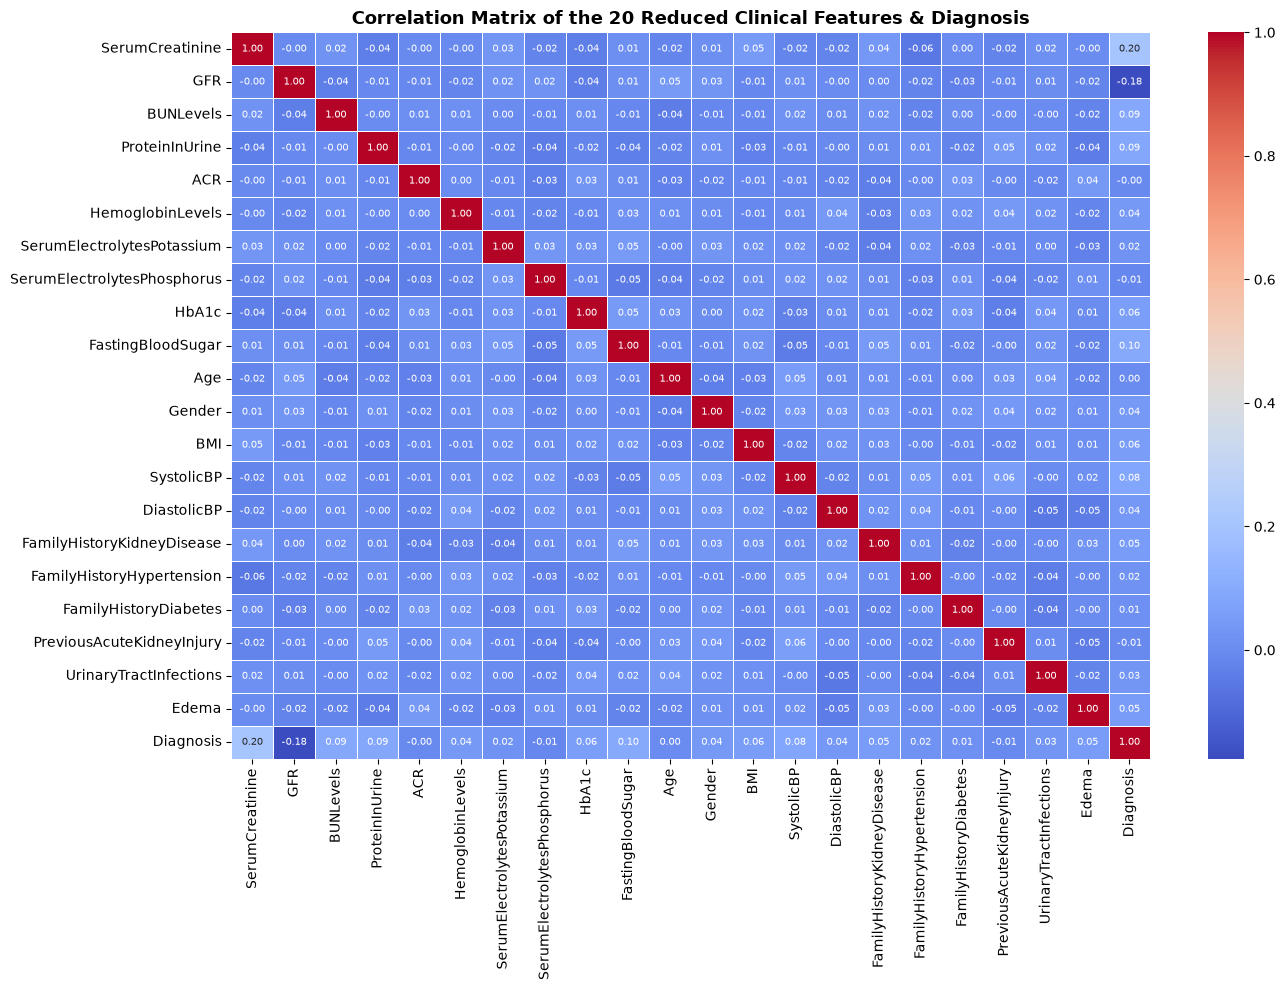

Training Set : (1327, 21)
Testing Set  : (332, 21)
Preprocessing Pipeline fitted and saved as ckd_preprocessor_20.pkl


In [ ]:
# Correlation Heatmap of the 21 Selected Features + Target
plt.figure(figsize=(14, 10))
corr = df_clean[selected_21_features + ['Diagnosis']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, annot_kws={'size': 7.5})
plt.title('Correlation Matrix of the 20 Reduced Clinical Features & Diagnosis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Preprocessing Pipeline (KNNImputer + StandardScaler)
preprocessor = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
joblib.dump(preprocessor, 'ckd_preprocessor_20.pkl')

print(f'Training Set : {X_train_scaled.shape}')
print(f'Testing Set  : {X_test_scaled.shape}')
print('Preprocessing Pipeline fitted and saved as ckd_preprocessor_20.pkl')

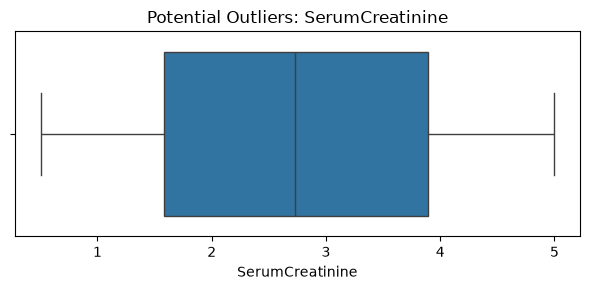

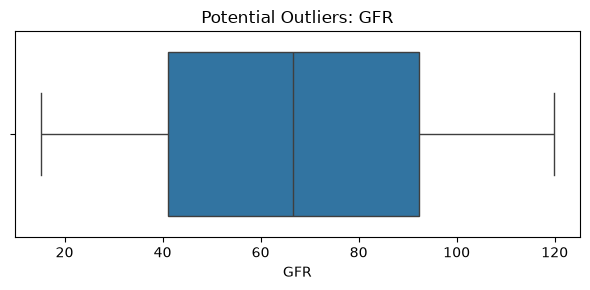

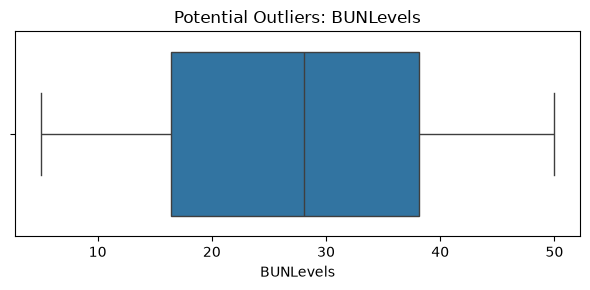

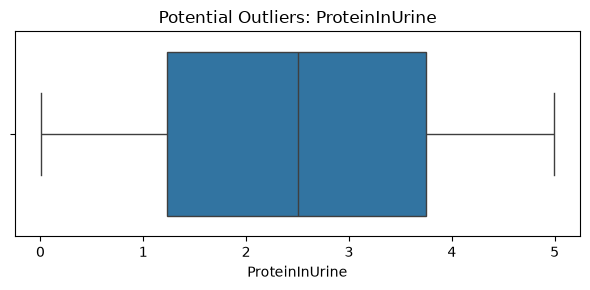

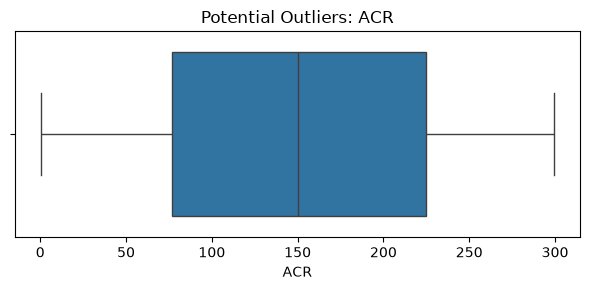

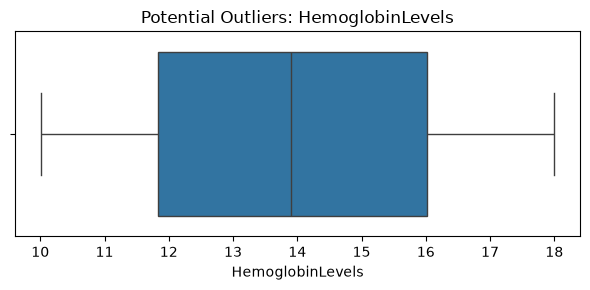

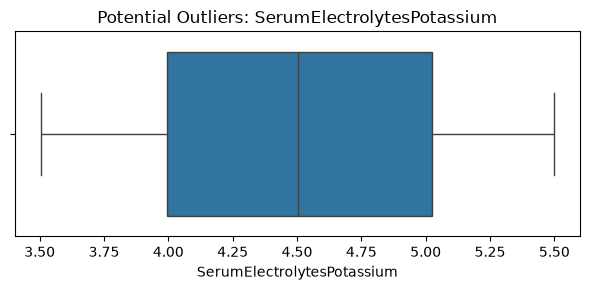

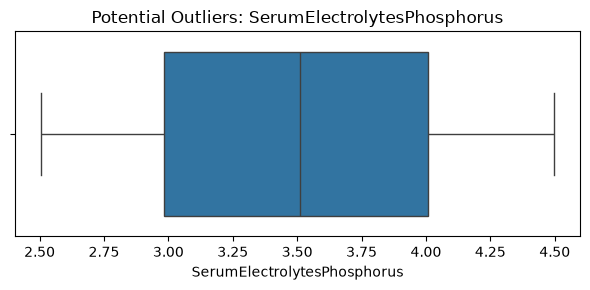

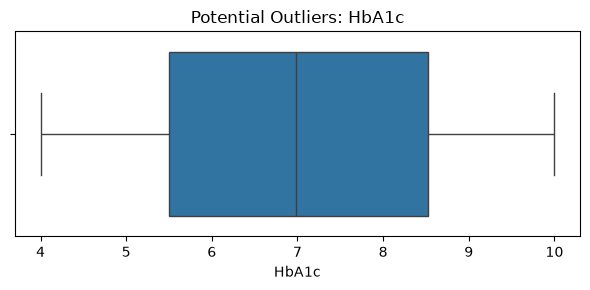

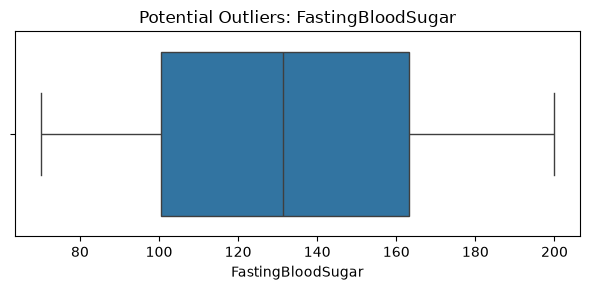

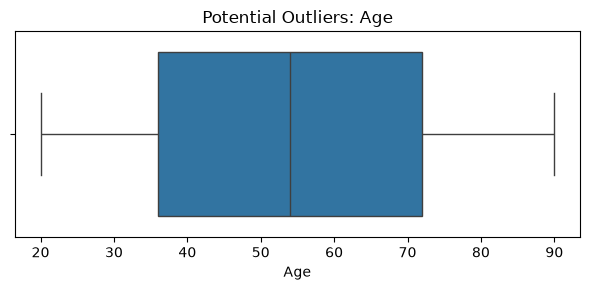

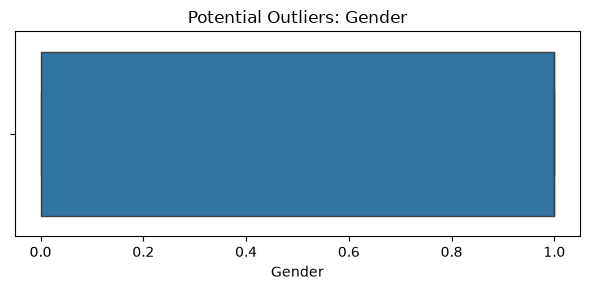

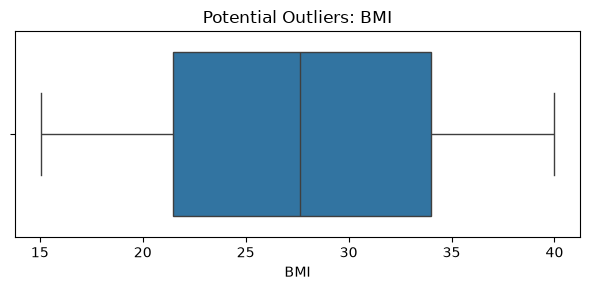

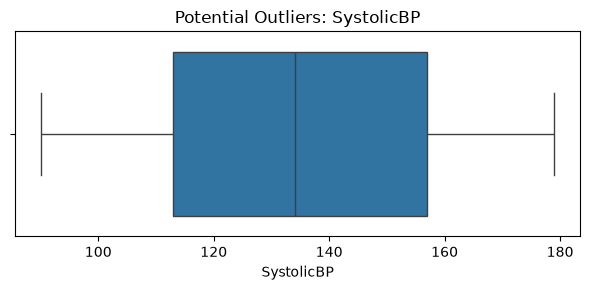

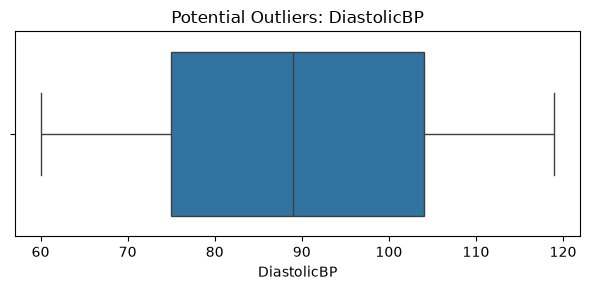

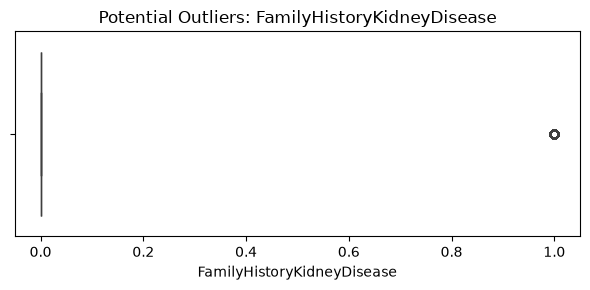

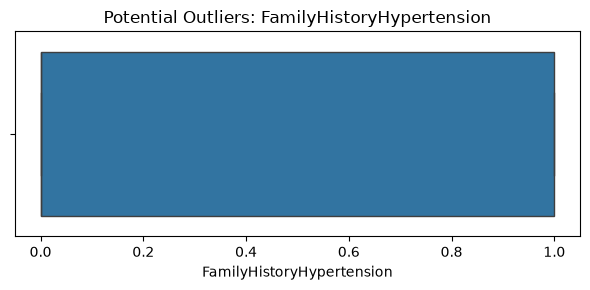

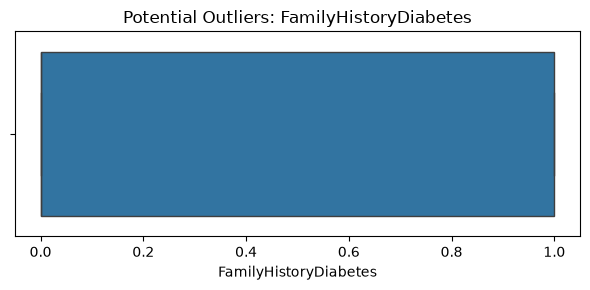

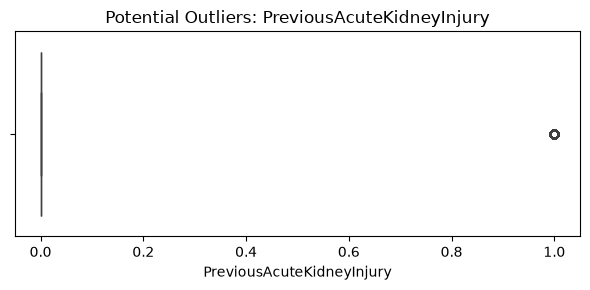

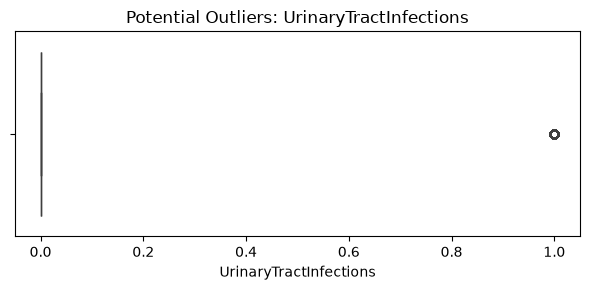

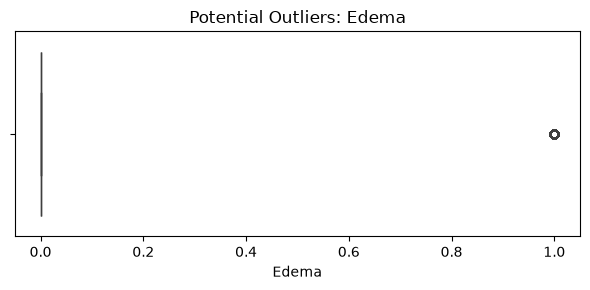

In [13]:
# 5 Number Summary The Selected Attributes

for col in X.select_dtypes(include=["int64", "float64"]).columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=X[col])
    plt.title(f"Potential Outliers: {col}")
    plt.tight_layout()
    plt.show()

## Shortlisting 6 Models (4 Normal + 2 Ensemble)
1. **Logistic Regression** *(Normal — Linear Classifier)*
2. **Support Vector Machine (SVM - RBF)** *(Normal — Kernel Classifier)*
3. **K-Nearest Neighbors (KNN)** *(Normal — Distance Classifier)*
4. **Multi-Layer Perceptron (MLP)** *(Normal — Feedforward Neural Network)*
5. **Random Forest** *(Ensemble 1 — Bagging)*
6. **Gradient Boosting** *(Ensemble 2 — Boosting)*